In [1]:
import sys
import cv2

print("Python version:", sys.version)
print("OpenCV version:", cv2.__version__)
print("Environment:", sys.executable)


Python version: 3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:13:05) [MSC v.1942 64 bit (AMD64)]
OpenCV version: 4.12.0
Environment: c:\Users\Alexia\miniconda3\envs\nisar\python.exe


In [2]:
%pip install nisar-pytools


     ---------------------------------------- 0.0/551.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/551.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/551.5 kB ? eta -:--:--
     ---------------------------------------- 0.0/551.5 kB ? eta -:--:--
     ------------------- -------------------- 262.1/551.5 kB ? eta -:--:--
     ---------------------------------------- 551.5/551.5 kB 1.2 MB/s  0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   -------------- ------------------------- 0.5/1

  error: subprocess-exited-with-error
  
  × Building wheel for snaphu (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [12 lines of output]
      *** scikit-build-core 1.1.2 using CMake 4.4.4 (wheel)
      *** Configuring CMake...
      loading initial cache file C:\Users\Alexia\AppData\Local\Temp\tmpbaks9qf2\build\CMakeInit.txt
      -- Building for: NMake Makefiles
      CMake Error at CMakeLists.txt:15 (message):
        Windows is not supported as a target platform.
      
      
      -- Configuring incomplete, errors occurred!
      
      *** CMake configuration failed
      [end of output]
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for snaphu
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> snaphu


In [3]:
%pip install requests pandas matplotlib rasterio asf_search

  Using cached pandas-3.1.1-cp312-cp312-win_amd64.whl.metadata (16 kB)
  Using cached rasterio-1.5.2-cp312-cp312-win_amd64.whl.metadata (8.9 kB)
  Using cached asf_search-14.1.0-py3-none-any.whl.metadata (11 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached affine-3.0.1-py3-none-any.whl.metadata (4.5 kB)
  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached shapely-2.2.0-cp312-cp312-win_amd64.whl.metadata (6.8 kB)
  Using cached pytz-2026.6-py2.py3-none-any.whl.metadata (22 kB)
  Using cached dateparser-1.5.0-py3-none-any.whl.metadata (55 kB)
  Using cached tenacity-9.2.1-py3-none-any.whl.metadata (1.4 kB)
  Using cached regex-2026.11.9-cp312-cp312-win_amd64.whl.metadata (41 kB)
  Using cached tzlocal-5.4.5-py3-none-any.whl.metadata (7.7 kB)
Using cached pandas-3.1.1-cp312-cp312-win_amd64.whl (10.8 MB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? et

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [4]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import asf_search

print("All imports successful!")

All imports successful!


In [1]:
import sys
import asf_search as asf
import pandas as pd
import matplotlib.pyplot as plt

print("Python location:", sys.executable)
print("ASF Search imported successfully")
print("Pandas and Matplotlib imported successfully")

Python location: c:\Users\Alexia\miniconda3\envs\nisar\python.exe
ASF Search imported successfully
Pandas and Matplotlib imported successfully


In [3]:

import asf_search as asf

# Approximate Le Morne study area
le_morne_aoi = (
    "POLYGON((57.299 -20.492, "
    "57.358 -20.492, "
    "57.358 -20.423, "
    "57.299 -20.423, "
    "57.299 -20.492))"
)

# Search NISAR GCOV products
le_morne_results = asf.search(
    dataset="NISAR",
    processingLevel="GCOV",
    intersectsWith=le_morne_aoi,
    maxResults=100
)

print("Products found:", len(le_morne_results))

for product in le_morne_results:
    print(product.properties.get("sceneName"))
    print("Date:", product.properties.get("startTime"))
    print("Product:", product.properties.get("processingLevel"))
    print("-" * 50)


Products found: 1
NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001
Date: 2026-10-23T14:18:44Z
Product: GCOV
--------------------------------------------------


In [4]:
# Search ALL NISAR product types for Le Morne
# No start date or end date: search all available dates

all_le_morne_results = asf.search(
    dataset="NISAR",
    intersectsWith=le_morne_aoi,
    maxResults=1000
)

import pandas as pd

records = []

for product in all_le_morne_results:
    p = product.properties

    records.append({
        "Date": p.get("startTime"),
        "Product": p.get("processingLevel"),
        "Scene": p.get("sceneName")
    })

df_le_morne = pd.DataFrame(records)

print("Total NISAR products found:", len(df_le_morne))

if not df_le_morne.empty:
    print("\nProducts by type:")
    print(df_le_morne["Product"].value_counts())

    print("\nAvailable observations:")
    display(df_le_morne.sort_values("Date").reset_index(drop=True))
else:
    print("No matching NISAR products found.")

Total NISAR products found: 1000

Products by type:
Product
ECMWF_SMST    990
RRSD            7
GSLC            1
GCOV            1
RSLC            1
Name: count, dtype: int64

Available observations:


,Date,Product,Scene
0,2026-10-08T02:03:48Z,RRSD,NISAR_L0_PR_RRSD_032_113_A_156S_20261008T02034...
1,2026-10-11T14:18:40Z,RRSD,NISAR_L0_PR_RRSD_032_164_D_156S_20261011T14184...
2,2026-10-20T02:03:48Z,RRSD,NISAR_L0_PR_RRSD_033_113_A_156S_20261020T02034...
3,2026-10-23T14:18:40Z,RRSD,NISAR_L0_PR_RRSD_033_164_D_156S_20261023T14184...
4,2026-10-23T14:18:44Z,GSLC,NISAR_L2_PR_GSLC_033_164_D_099_4005_DHDH_A_202...
...,...,...,...
995,NaN,ECMWF_SMST,ECMWF_SMST_202610021200_202610021200_1
996,NaN,ECMWF_SMST,ECMWF_SMST_202610020600_202610021100_1
997,NaN,ECMWF_SMST,ECMWF_SMST_202610020600_202610021000_1
998,NaN,ECMWF_SMST,ECMWF_SMST_202610020600_202610020900_1


In [5]:
# Inspect the GCOV observation we found

for product in le_morne_results:
    print("FULL PRODUCT INFORMATION")
    for key, value in product.properties.items():
        print(f"{key}: {value}")
        

FULL PRODUCT INFORMATION
centerLat: None
centerLon: None
stopTime: 2026-10-23T14:18:57Z
fileID: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001
flightDirection: DESCENDING
pathNumber: 164
processingLevel: GCOV
url: https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GCOV_V1/NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001/NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001.h5
startTime: 2026-10-23T14:18:44Z
sceneName: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001
browse: ['https://nisar.asf.earthdatacloud.nasa.gov/BROWSE/NISAR_L2_GCOV_V1/NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001/NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_LATLON.png', 'https://nisar.asf.earthdatacloud.nasa.gov/BROWSE/NISAR_L2_GCOV_V1/NISAR_L2_PR_GC

Browse images found: 7
Image downloaded successfully!
File size: 1120.44 KB


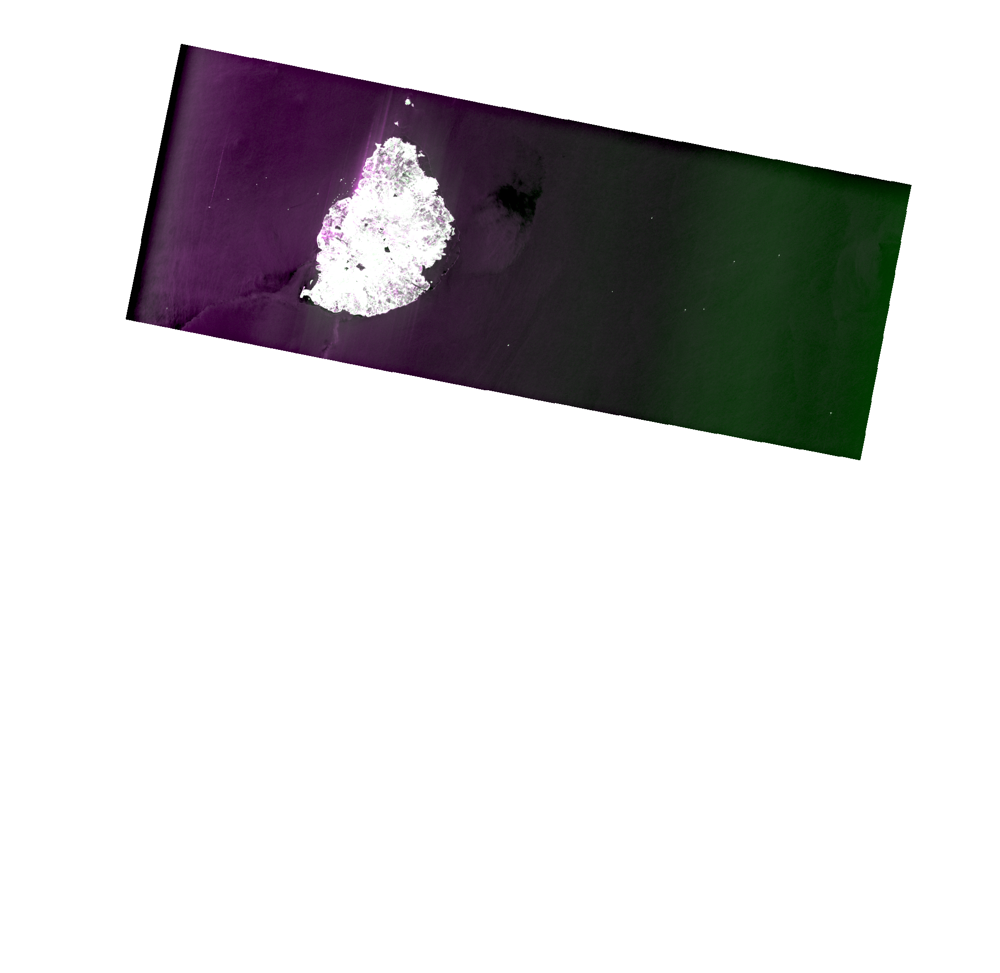

In [6]:
import requests
from IPython.display import display, Image

# Get the browse image URL from our GCOV result
gcov_product = le_morne_results[0]
browse_urls = gcov_product.properties.get("browse", [])

print("Browse images found:", len(browse_urls))

if browse_urls:
    browse_url = browse_urls[0]

    response = requests.get(browse_url, timeout=60)
    response.raise_for_status()

    print("Image downloaded successfully!")
    print("File size:", round(len(response.content) / 1024, 2), "KB")

    display(Image(data=response.content))
else:
    print("No browse image available for this product.")


Browse image 1: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_LATLON.png
Size: 1120.44 KB
Dimensions: (1956, 1905)


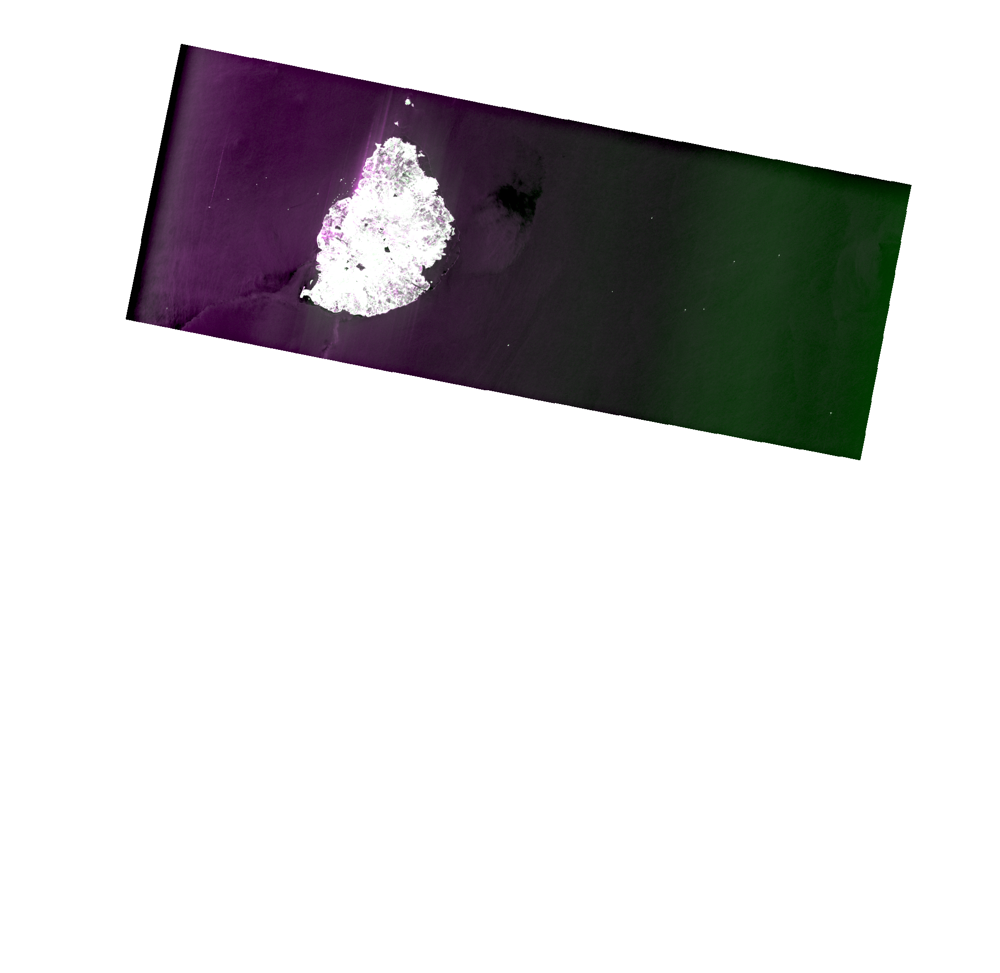


Browse image 2: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_LATLON_thumbnail.png
Size: 3.92 KB
Dimensions: (100, 100)


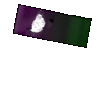


Browse image 3: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE.png
Size: 1364.78 KB
Dimensions: (1956, 1901)


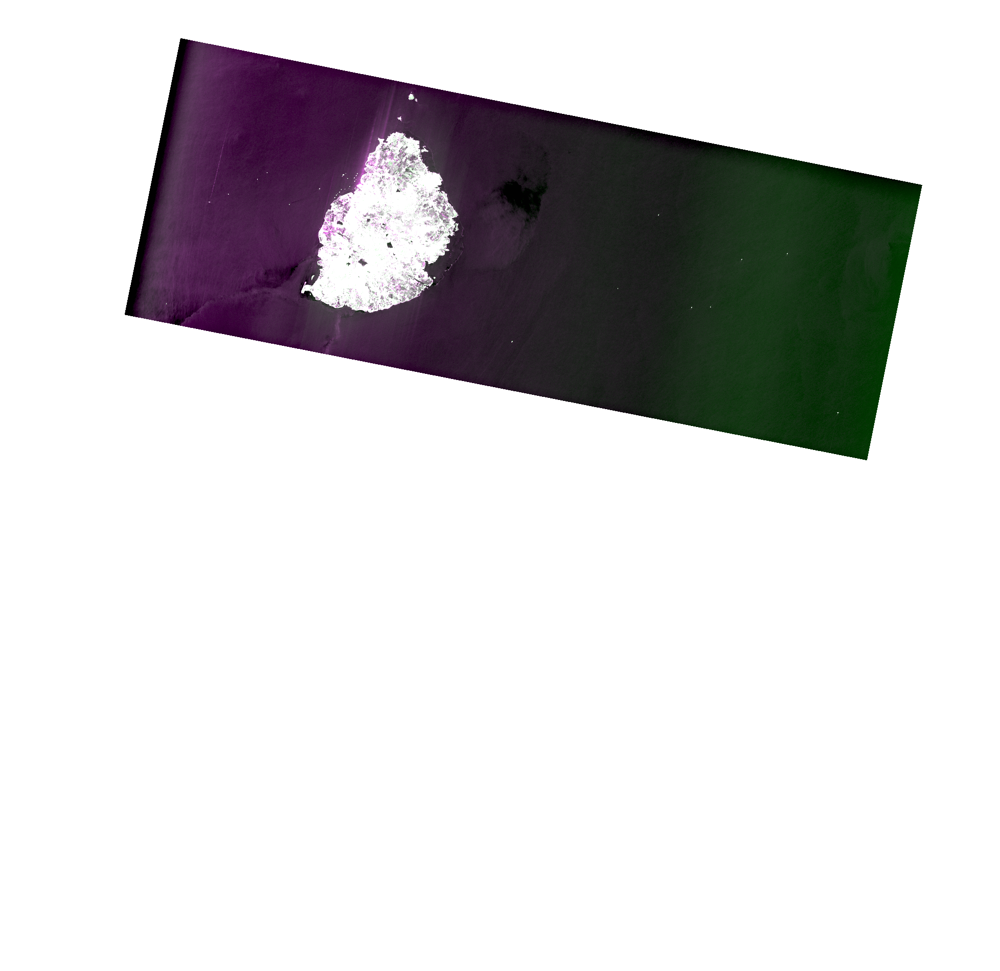


Browse image 4: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE_A_HHHH.png
Size: 467.93 KB
Dimensions: (1956, 1901)


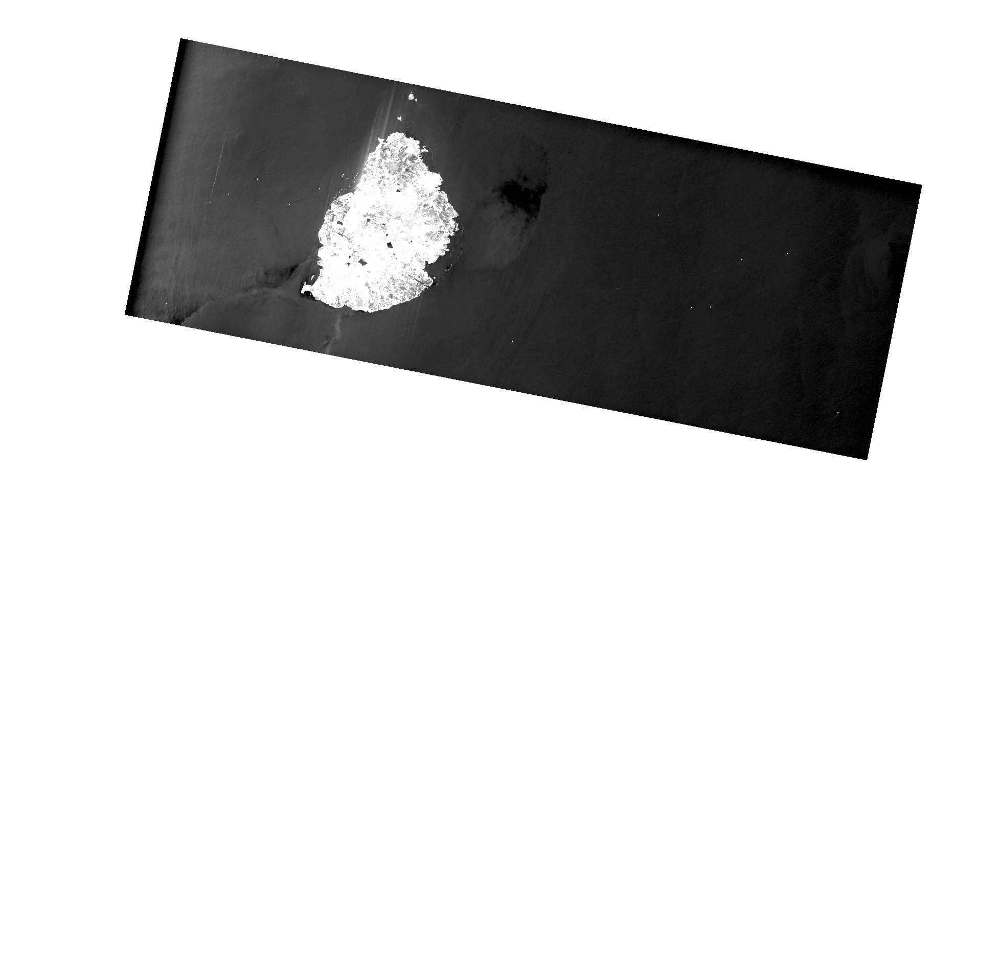


Browse image 5: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE_A_HVHV.png
Size: 460.66 KB
Dimensions: (1956, 1901)


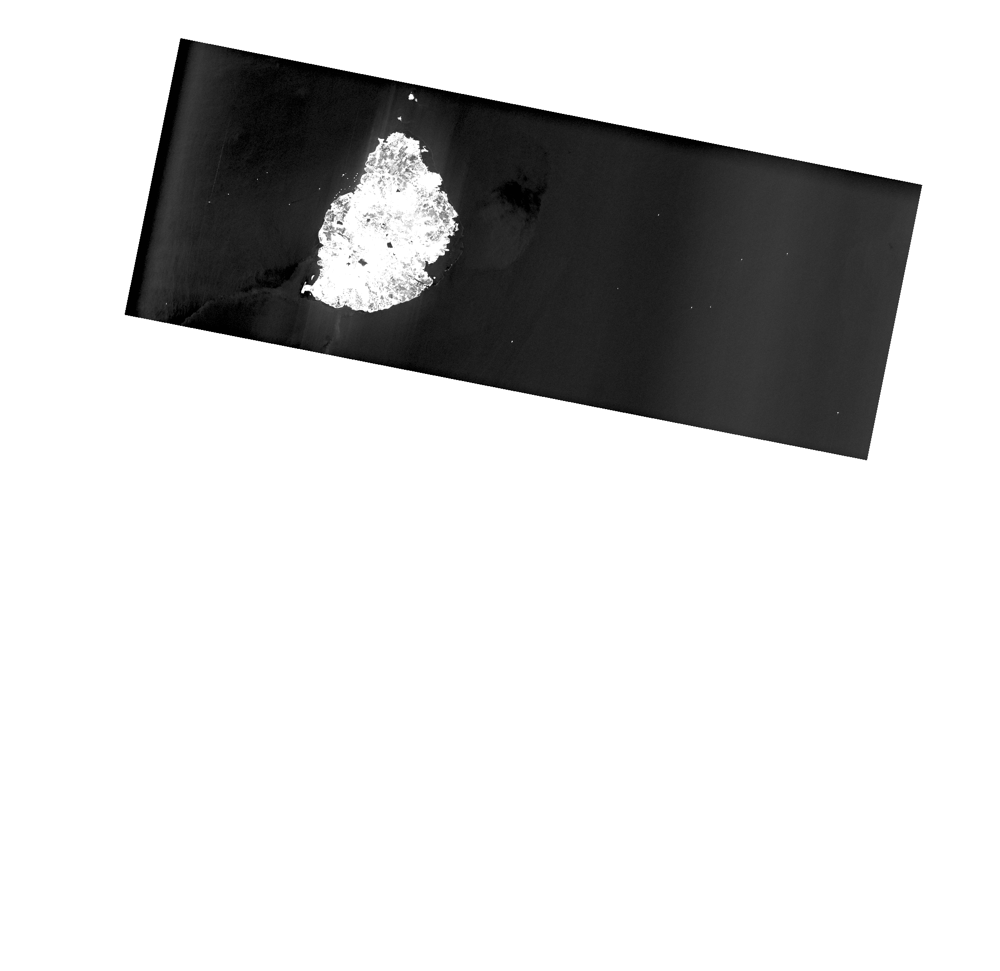


Browse image 6: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE_B_HHHH.png
Size: 255.08 KB
Dimensions: (1386, 1347)


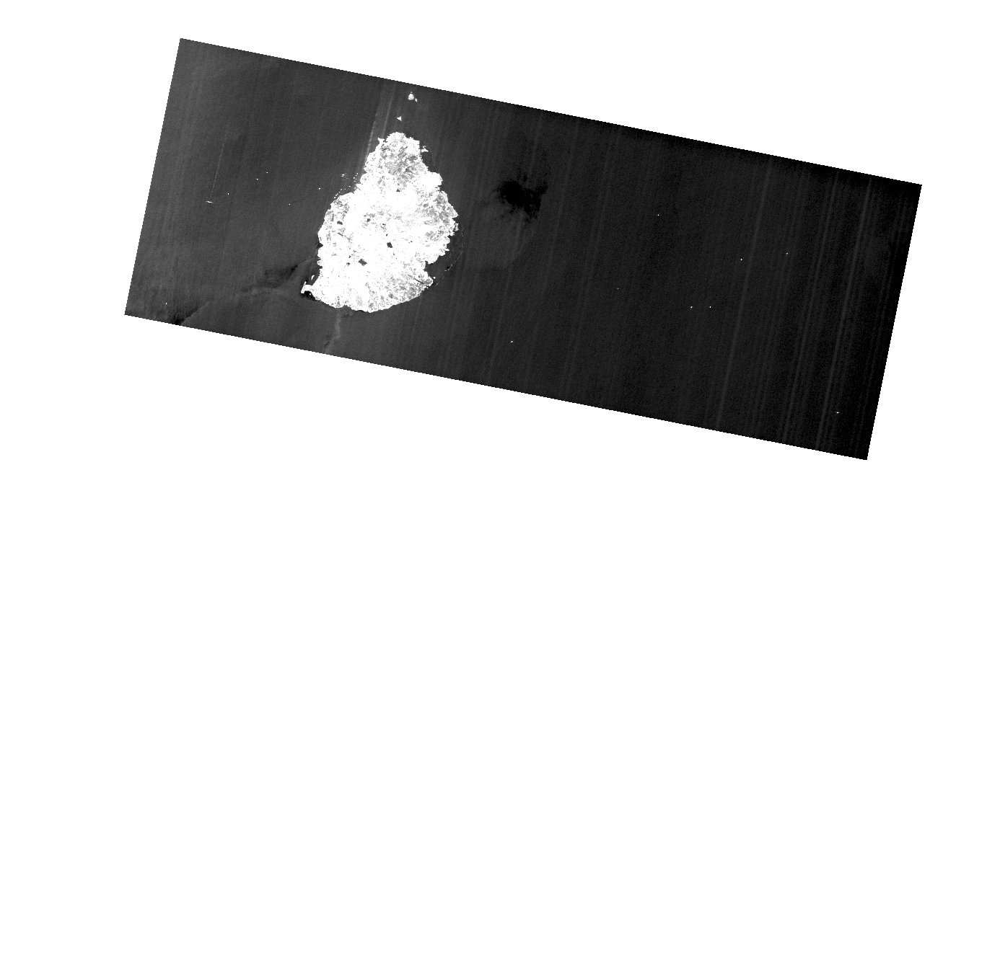


Browse image 7: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE_B_HVHV.png
Size: 274.8 KB
Dimensions: (1386, 1347)


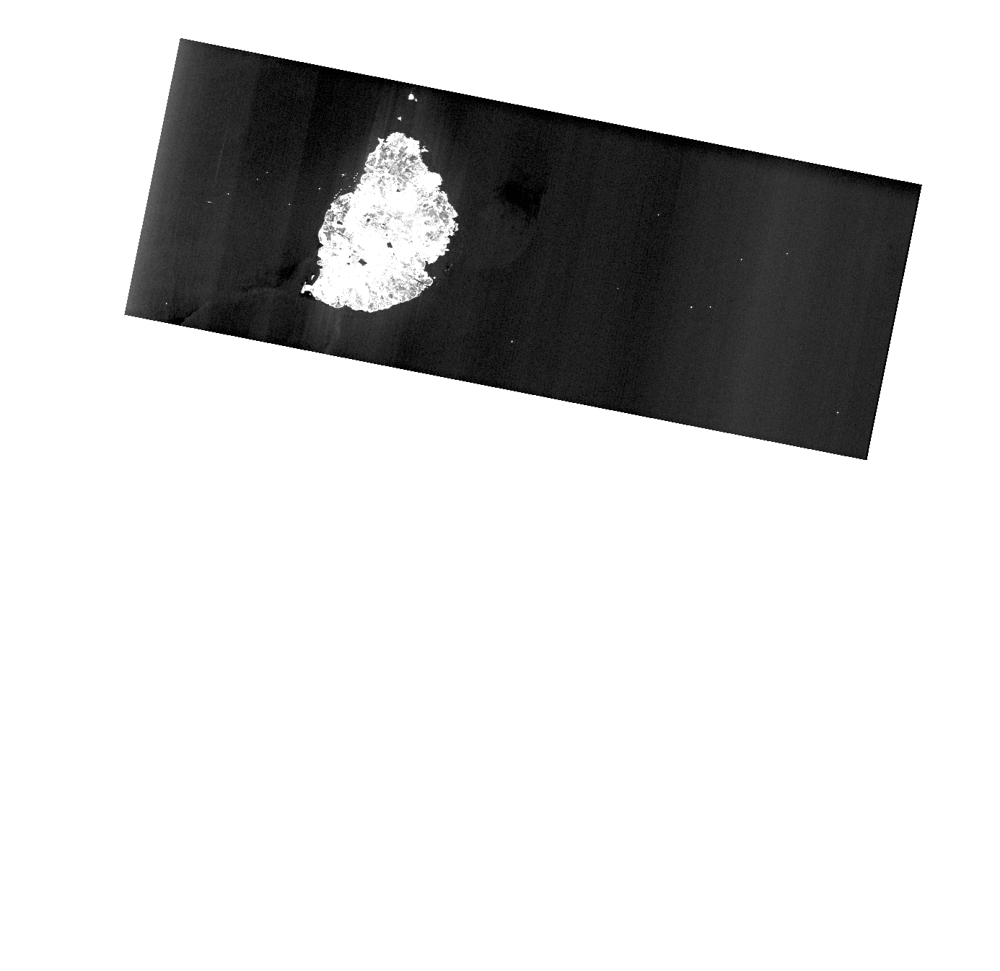

In [7]:
from urllib.parse import urlparse
from pathlib import Path
from io import BytesIO
from PIL import Image as PILImage
from IPython.display import display, Image as DisplayImage

browse_urls = gcov_product.properties.get("browse", [])

for i, url in enumerate(browse_urls, start=1):
    response = requests.get(url, timeout=60)
    response.raise_for_status()

    filename = Path(urlparse(url).path).name

    print(f"\nBrowse image {i}: {filename}")
    print("Size:", round(len(response.content) / 1024, 2), "KB")

    try:
        img = PILImage.open(BytesIO(response.content))
        print("Dimensions:", img.size)
        display(DisplayImage(data=response.content, width=650))
    except Exception:
        print("This URL does not contain a directly displayable image.")
        

In [8]:
from pathlib import Path
from urllib.parse import urlparse

for i, url in enumerate(browse_urls, start=1):
    filename = Path(urlparse(url).path).name
    print(f"Image {i}: {filename}")
    

Image 1: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_LATLON.png
Image 2: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_LATLON_thumbnail.png
Image 3: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE.png
Image 4: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE_A_HHHH.png
Image 5: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE_A_HVHV.png
Image 6: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE_B_HHHH.png
Image 7: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE_B_HVHV.png


In [10]:
%pip install h5py

  Using cached h5py-3.16.0-cp312-cp312-win_amd64.whl.metadata (3.1 kB)
Using cached h5py-3.16.0-cp312-cp312-win_amd64.whl (3.2 MB)
Note: you may need to restart the kernel to use updated packages.


In [11]:
import h5py

# Display the GCOV product's downloadable file information
gcov_files = gcov_product.properties["bytes"]

for filename, information in gcov_files.items():
    print("Filename:", filename)
    print("Format:", information["format"])
    print("Size (GB):", round(information["bytes"] / 1e9, 2))

Filename: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001.h5
Format: HDF5
Size (GB): 1.9
Filename: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_LATLON.png
Format: PNG
Size (GB): 0.0
Filename: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE.png
Format: PNG
Size (GB): 0.0
Filename: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE_A_HHHH.png
Format: PNG
Size (GB): 0.0
Filename: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE_A_HVHV.png
Format: PNG
Size (GB): 0.0
Filename: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE_B_HHHH.png
Format: PNG
Size (GB): 0.0
Filename: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001_NATIVE_B_HVHV.png
Format: PNG
Size (GB): 0.0

In [12]:
import shutil
from pathlib import Path

download_dir = Path.home() / "Documents" / "NISAR_LeMorne"
download_dir.mkdir(parents=True, exist_ok=True)

free_gb = shutil.disk_usage(download_dir).free / (1024**3)

print("Download folder:", download_dir)
print("Free disk space:", round(free_gb, 2), "GB")

Download folder: C:\Users\Alexia\Documents\NISAR_LeMorne
Free disk space: 385.53 GB


In [13]:
from getpass import getpass

username = input("Earthdata username: ")
password = getpass("Earthdata password: ")

session = asf.ASFSession().auth_with_creds(
    username, password
)

print("Authentication successful!")

# Download only our selected GCOV science file
gcov_product.download(
    path=str(download_dir),
    session=session
)

print("Download completed!")

Authentication successful!
Download completed!


In [14]:
import h5py

# Locate our downloaded GCOV file
h5_files = list(download_dir.glob("*.h5"))

h5_path = h5_files[0]

print("File:", h5_path.name)

# Open in read-only mode
# This does NOT load the entire file into RAM
with h5py.File(h5_path, "r") as f:

    print("\nRelevant scientific datasets:\n")

    def inspect(name, obj):
        if isinstance(obj, h5py.Dataset):
            if any(key in name.lower() for key in
                   ["hhhh", "hvhv", "latitude",
                    "longitude", "xcoordinates",
                    "ycoordinates", "projection"]):

                print("Dataset:", name)
                print("Shape:", obj.shape)
                print("Data type:", obj.dtype)
                print("Chunks:", obj.chunks)
                print("-" * 40)

    f.visititems(inspect)

File: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001.h5

Relevant scientific datasets:

Dataset: science/LSAR/GCOV/grids/frequencyA/HHHH
Shape: (32328, 33264)
Data type: float32
Chunks: (512, 512)
----------------------------------------
Dataset: science/LSAR/GCOV/grids/frequencyA/HVHV
Shape: (32328, 33264)
Data type: float32
Chunks: (512, 512)
----------------------------------------
Dataset: science/LSAR/GCOV/grids/frequencyA/projection
Shape: ()
Data type: uint32
Chunks: None
----------------------------------------
Dataset: science/LSAR/GCOV/grids/frequencyA/xCoordinateSpacing
Shape: ()
Data type: float64
Chunks: None
----------------------------------------
Dataset: science/LSAR/GCOV/grids/frequencyA/xCoordinates
Shape: (33264,)
Data type: float64
Chunks: None
----------------------------------------
Dataset: science/LSAR/GCOV/grids/frequencyA/yCoordinateSpacing
Shape: ()
Data type: float64
Chunks: None
---------------------------------

In [15]:
with h5py.File(h5_path, "r") as f:

    grid = f["science/LSAR/GCOV/grids/frequencyA"]

    print("AVAILABLE DATASETS")
    print("-" * 45)

    for name, obj in grid.items():
        if isinstance(obj, h5py.Dataset):
            print(name, "| Shape:", obj.shape, "| Type:", obj.dtype)

    print("\nRADAR MEASUREMENT INFORMATION")
    print("-" * 45)

    for name in ["HHHH", "HVHV"]:
        ds = grid[name]
        print("\n", name)
        for key, value in ds.attrs.items():
            print(key, ":", value)

    print("\nGEOGRAPHIC INFORMATION")
    print("-" * 45)

    for name in ["xCoordinates", "yCoordinates", "projection"]:
        if name in grid:
            ds = grid[name]
            print("\n", name)
            print("Shape:", ds.shape)

            if name == "projection":
                print("Projection value:", ds[()])

            elif ds.ndim == 1:
                print("First 5:", ds[:5])
                print("Last 5:", ds[-5:])
                if len(ds) > 1:
                    print("Average spacing:",
                          abs(float(ds[1]) - float(ds[0])))

AVAILABLE DATASETS
---------------------------------------------
HHHH | Shape: (32328, 33264) | Type: float32
HVHV | Shape: (32328, 33264) | Type: float32
inputDataExceptionMask | Shape: (32328, 33264) | Type: uint16
listOfCovarianceTerms | Shape: (2,) | Type: |S4
listOfPolarizations | Shape: (2,) | Type: |S2
mask | Shape: (32328, 33264) | Type: uint8
numberOfLooks | Shape: (32328, 33264) | Type: float32
numberOfSubSwaths | Shape: () | Type: uint8
projection | Shape: () | Type: uint32
rtcGammaToSigmaFactor | Shape: (32328, 33264) | Type: float32
xCoordinateSpacing | Shape: () | Type: float64
xCoordinates | Shape: (33264,) | Type: float64
yCoordinateSpacing | Shape: () | Type: float64
yCoordinates | Shape: (32328,) | Type: float64

RADAR MEASUREMENT INFORMATION
---------------------------------------------

 HHHH
DIMENSION_LIST : [array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)]
_FillValue : nan
description : b'Covariance between HH and HH'

In [17]:
import h5py

with h5py.File(h5_path, "r") as f:
    print("NISAR FILE METADATA:\n")

    def show_metadata(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"\nDataset: {name}")
            print("Shape:", obj.shape)
            print("Data type:", obj.dtype)

        for key, value in obj.attrs.items():
            print(f"  {key}: {value}")

    f.visititems(show_metadata)

NISAR FILE METADATA:


Dataset: science/LSAR/GCOV/grids/frequencyA/HHHH
Shape: (32328, 33264)
Data type: float32
  DIMENSION_LIST: [array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)]
  _FillValue: nan
  description: b'Covariance between HH and HH'
  grid_mapping: b'projection'
  long_name: b'Geocoded polarimetric covariance term HHHH'
  max_value: 2476.712890625
  mean_value: 0.03372466564178467
  min_value: 1.453569893783424e-06
  sample_stddev: 0.6068081855773926
  units: b'1'
  valid_min: 0.0

Dataset: science/LSAR/GCOV/grids/frequencyA/HVHV
Shape: (32328, 33264)
Data type: float32
  DIMENSION_LIST: [array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)]
  _FillValue: nan
  description: b'Covariance between HV and HV'
  grid_mapping: b'projection'
  long_name: b'Geocoded polarimetric covariance term HVHV'
  max_value: 1075.745849609375
  mean_value: 0.008415973745286465
  min_value: 4.2947635847667

In [18]:
with h5py.File(h5_path, "r") as f:

    grid = f["science/LSAR/GCOV/grids/frequencyA"]

    print("GRID METADATA:\n")

    for name, obj in grid.items():
        if isinstance(obj, h5py.Dataset):
            print(name, "| Shape:", obj.shape)

    print("\nGRID ATTRIBUTES:\n")

    for key, value in grid.attrs.items():
        print(key, ":", value)

GRID METADATA:

HHHH | Shape: (32328, 33264)
HVHV | Shape: (32328, 33264)
inputDataExceptionMask | Shape: (32328, 33264)
listOfCovarianceTerms | Shape: (2,)
listOfPolarizations | Shape: (2,)
mask | Shape: (32328, 33264)
numberOfLooks | Shape: (32328, 33264)
numberOfSubSwaths | Shape: ()
projection | Shape: ()
rtcGammaToSigmaFactor | Shape: (32328, 33264)
xCoordinateSpacing | Shape: ()
xCoordinates | Shape: (33264,)
yCoordinateSpacing | Shape: ()
yCoordinates | Shape: (32328,)

GRID ATTRIBUTES:



In [19]:
with h5py.File(h5_path, "r") as f:

    grid = f["science/LSAR/GCOV/grids/frequencyA"]

    x_spacing = grid["xCoordinateSpacing"][()]
    y_spacing = grid["yCoordinateSpacing"][()]

    print("NISAR X pixel spacing:", x_spacing, "metres")
    print("NISAR Y pixel spacing:", y_spacing, "metres")

NISAR X pixel spacing: 10.0 metres
NISAR Y pixel spacing: -10.0 metres


In [16]:
with h5py.File(h5_path, "r") as f:

    grid = f["science/LSAR/GCOV/grids/frequencyA"]

    # Inspect radar measurement information
    for name in ["HHHH", "HVHV"]:
        ds = grid[name]

        print(f"\n{name}")
        print("Description:", ds.attrs.get("description"))
        print("Units:", ds.attrs.get("units"))
        print("Fill value:", ds.attrs.get("_FillValue"))

    # Inspect geographic coordinates
    for name in ["xCoordinates", "yCoordinates"]:
        ds = grid[name]
        coords = ds[:]

        print(f"\n{name}")
        print("First coordinate:", coords[0])
        print("Last coordinate:", coords[-1])
        print("Minimum:", coords.min())
        print("Maximum:", coords.max())
        print("Spacing:", coords[1] - coords[0])
        print("Units:", ds.attrs.get("units"))

    # Inspect projection
    projection = grid["projection"]

    print("\nProjection:", projection[()])
    print("EPSG attribute:",
          projection.attrs.get("epsg_code"))

    # Inspect nominal pixel spacing
    print("\nPixel spacing:")
    print("X:", grid["xCoordinateSpacing"][()])
    print("Y:", grid["yCoordinateSpacing"][()])


HHHH
Description: b'Covariance between HH and HH'
Units: b'1'
Fill value: nan

HVHV
Description: b'Covariance between HV and HV'
Units: b'1'
Fill value: nan

xCoordinates
First coordinate: 432005.0
Last coordinate: 764635.0
Minimum: 432005.0
Maximum: 764635.0
Spacing: 10.0
Units: b'meters'

yCoordinates
First coordinate: 7834315.0
Last coordinate: 7511045.0
Minimum: 7511045.0
Maximum: 7834315.0
Spacing: -10.0
Units: b'meters'

Projection: 32740
EPSG attribute: 32740

Pixel spacing:
X: 10.0
Y: -10.0


In [18]:
%pip install pyproj

  Using cached pyproj-3.8.0-cp312-cp312-win_amd64.whl.metadata (40 kB)
Using cached pyproj-3.8.0-cp312-cp312-win_amd64.whl (6.7 MB)
Note: you may need to restart the kernel to use updated packages.


In [19]:
import numpy as np
from pyproj import Transformer

# Convert geographic coordinates to NISAR's UTM projection
transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32740",
    always_xy=True
)

# Approximate Le Morne study boundary
corners = [
    (57.299, -20.492),
    (57.358, -20.492),
    (57.358, -20.423),
    (57.299, -20.423)
]

projected = [
    transformer.transform(lon, lat)
    for lon, lat in corners
]

xmin = min(p[0] for p in projected)
xmax = max(p[0] for p in projected)
ymin = min(p[1] for p in projected)
ymax = max(p[1] for p in projected)

with h5py.File(h5_path, "r") as f:

    grid = f["science/LSAR/GCOV/grids/frequencyA"]

    x = grid["xCoordinates"][:]
    y = grid["yCoordinates"][:]

    cols = np.where((x >= xmin) & (x <= xmax))[0]
    rows = np.where((y >= ymin) & (y <= ymax))[0]

    if len(rows) == 0 or len(cols) == 0:
        print("Study area does not overlap the raster.")
    else:
        r0, r1 = rows.min(), rows.max() + 1
        c0, c1 = cols.min(), cols.max() + 1

        print("LE MORNE PIXEL WINDOW")
        print("Rows:", r0, "to", r1)
        print("Columns:", c0, "to", c1)
        print("Subset dimensions:", r1-r0, "x", c1-c0)

        size_mb = (r1-r0) * (c1-c0) * 4 / 1e6
        print("Approx. memory for one float32 layer:",
              round(size_mb, 2), "MB")

LE MORNE PIXEL WINDOW
Rows: 9264 to 10029
Columns: 9918 to 10535
Subset dimensions: 765 x 617
Approx. memory for one float32 layer: 1.89 MB


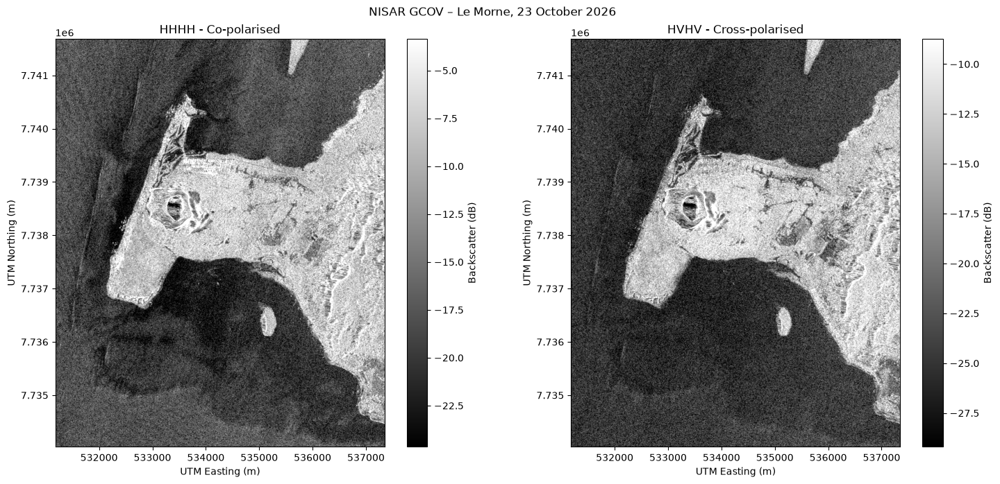

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import h5py

with h5py.File(h5_path, "r") as f:

    grid = f["science/LSAR/GCOV/grids/frequencyA"]

    # Extract only the Le Morne pixel window
    hh = grid["HHHH"][r0:r1, c0:c1]
    hv = grid["HVHV"][r0:r1, c0:c1]

    # Extract matching geographic coordinates
    x_sub = grid["xCoordinates"][c0:c1]
    y_sub = grid["yCoordinates"][r0:r1]


# Convert linear radar power into decibels
def to_db(data):
    result = np.full(data.shape, np.nan, dtype=np.float32)

    valid = np.isfinite(data) & (data > 0)

    result[valid] = 10 * np.log10(data[valid])

    return result


hh_db = to_db(hh)
hv_db = to_db(hv)

# Geographic extent, using 10 m pixel spacing
extent = [
    x_sub[0] - 5,
    x_sub[-1] + 5,
    y_sub[-1] - 5,
    y_sub[0] + 5
]

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

for ax, data, title in [
    (axes[0], hh_db, "HHHH - Co-polarised"),
    (axes[1], hv_db, "HVHV - Cross-polarised")
]:

    image = ax.imshow(
        data,
        cmap="gray",
        origin="upper",
        extent=extent,
        aspect="equal",
        vmin=np.nanpercentile(data, 2),
        vmax=np.nanpercentile(data, 98)
    )

    ax.set_title(title)
    ax.set_xlabel("UTM Easting (m)")
    ax.set_ylabel("UTM Northing (m)")

    plt.colorbar(image, ax=ax, label="Backscatter (dB)")

plt.suptitle("NISAR GCOV – Le Morne, 23 October 2026")
plt.tight_layout()
plt.show()

LE MORNE QUALITY MASK
---------------------
Total pixels: 472005
Valid pixels: 471928
Invalid/outside pixels: 77
Valid percentage: 99.98 %

Mask values and counts:
Value 0: 77 pixels
Value 1: 471928 pixels


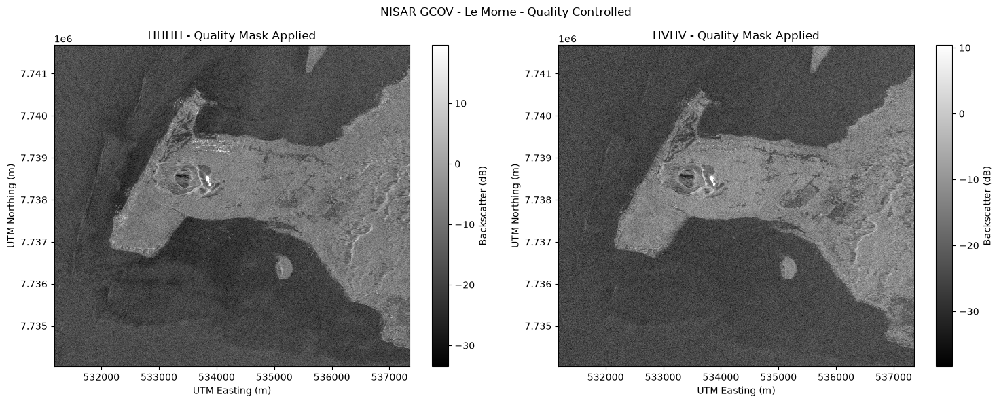

In [24]:

import numpy as np
import h5py
import matplotlib.pyplot as plt

with h5py.File(h5_path, "r") as f:

    grid = f["science/LSAR/GCOV/grids/frequencyA"]

    # Extract the mask for our Le Morne subset
    quality_mask = grid["mask"][r0:r1, c0:c1]

    # Read the radar measurements
    hh = grid["HHHH"][r0:r1, c0:c1]
    hv = grid["HVHV"][r0:r1, c0:c1]

    # Geographic coordinates
    x_sub = grid["xCoordinates"][c0:c1]
    y_sub = grid["yCoordinates"][r0:r1]

# Valid pixels: fully focused radar samples
valid = (quality_mask > 0) & (quality_mask < 255)

# Print quality statistics
total = quality_mask.size
valid_count = np.count_nonzero(valid)
invalid_count = total - valid_count

print("LE MORNE QUALITY MASK")
print("---------------------")
print("Total pixels:", total)
print("Valid pixels:", valid_count)
print("Invalid/outside pixels:", invalid_count)
print("Valid percentage:", round(valid_count / total * 100, 2), "%")

print("\nMask values and counts:")
values, counts = np.unique(quality_mask, return_counts=True)

for value, count in zip(values, counts):
    print(f"Value {value}: {count} pixels")

# Convert radar power into decibels
def to_db(data):
    result = np.full(data.shape, np.nan, dtype=np.float32)
    good = np.isfinite(data) & (data > 0)
    result[good] = 10 * np.log10(data[good])
    return result

hh_db = to_db(hh)
hv_db = to_db(hv)

# Apply quality mask
hh_masked = np.where(valid, hh_db, np.nan)
hv_masked = np.where(valid, hv_db, np.nan)

# Plot the masked measurements
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, data, title in zip(
    axes,
    [hh_masked, hv_masked],
    ["HHHH - Quality Mask Applied", "HVHV - Quality Mask Applied"]
):
    image = ax.pcolormesh(
        x_sub,
        y_sub,
        data,
        shading="auto",
        cmap="gray"
    )
    ax.set_title(title)
    ax.set_xlabel("UTM Easting (m)")
    ax.set_ylabel("UTM Northing (m)")
    plt.colorbar(image, ax=ax, label="Backscatter (dB)")

plt.suptitle("NISAR GCOV - Le Morne - Quality Controlled")
plt.tight_layout()
plt.show()


Exploratory HHHH threshold: -13.7 dB


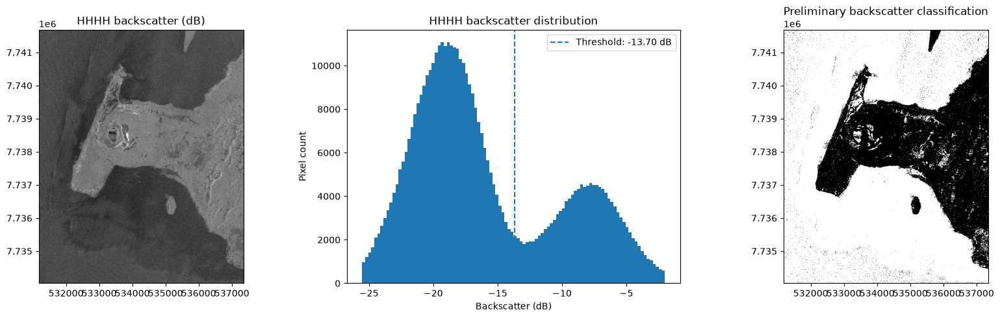

In [27]:

import numpy as np
import matplotlib.pyplot as plt

# Use valid HHHH measurements in dB
values = hh_masked[np.isfinite(hh_masked)]

# Limit histogram range to reduce extreme outlier influence
low, high = np.percentile(values, [1, 99])

hist, edges = np.histogram(
    values,
    bins=512,
    range=(low, high)
)

centres = (edges[:-1] + edges[1:]) / 2
weights = hist.astype(float)

# Otsu threshold calculation
weight_low = np.cumsum(weights)
weight_high = weights.sum() - weight_low

sum_low = np.cumsum(weights * centres)
total_sum = sum_low[-1]

mean_low = sum_low / np.maximum(weight_low, 1)
mean_high = (
    total_sum - sum_low
) / np.maximum(weight_high, 1)

between_variance = (
    weight_low * weight_high *
    (mean_low - mean_high) ** 2
)

# Ignore empty histogram classes
between_variance[
    (weight_low == 0) | (weight_high == 0)
] = 0

threshold = centres[np.argmax(between_variance)]

print("Exploratory HHHH threshold:", round(threshold, 2), "dB")

# Preliminary classification:
# 1 = lower backscatter candidate
# 0 = higher backscatter candidate

classification = np.full(hh_masked.shape, np.nan)

valid_pixels = np.isfinite(hh_masked)

classification[valid_pixels] = (
    hh_masked[valid_pixels] < threshold
).astype(float)

# Plot results
extent = [
    x_sub[0] - 5,
    x_sub[-1] + 5,
    y_sub[-1] - 5,
    y_sub[0] + 5
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].imshow(
    hh_masked,
    cmap="gray",
    extent=extent,
    origin="upper"
)
axes[0].set_title("HHHH backscatter (dB)")

axes[1].hist(values, bins=100, range=(low, high))
axes[1].axvline(
    threshold,
    linestyle="--",
    label=f"Threshold: {threshold:.2f} dB"
)
axes[1].set_title("HHHH backscatter distribution")
axes[1].set_xlabel("Backscatter (dB)")
axes[1].set_ylabel("Pixel count")
axes[1].legend()

axes[2].imshow(
    classification,
    cmap="gray",
    extent=extent,
    origin="upper",
    vmin=0,
    vmax=1
)
axes[2].set_title("Preliminary backscatter classification")

plt.tight_layout()
plt.show()


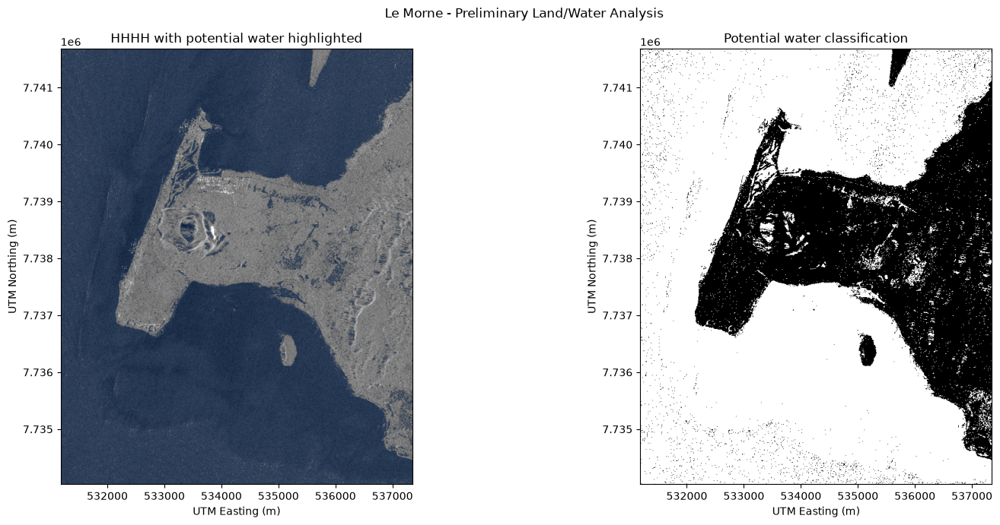

Potential water pixels: 327854
Other valid pixels: 144074


In [28]:

import numpy as np
import matplotlib.pyplot as plt

# Recreate the water candidate mask
water_candidate = (
    np.isfinite(hh_masked) &
    (hh_masked < threshold)
)

# Hide all pixels that are not classified as potential water
water_overlay = np.ma.masked_where(
    ~water_candidate,
    np.ones_like(hh_masked)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Original radar image with potential water highlighted
axes[0].imshow(
    hh_masked,
    cmap="gray",
    extent=extent,
    origin="upper"
)

axes[0].imshow(
    water_overlay,
    cmap="Blues",
    alpha=0.45,
    extent=extent,
    origin="upper",
    vmin=0,
    vmax=1
)

axes[0].set_title("HHHH with potential water highlighted")
axes[0].set_xlabel("UTM Easting (m)")
axes[0].set_ylabel("UTM Northing (m)")

# Binary classification
axes[1].imshow(
    water_candidate,
    cmap="gray",
    extent=extent,
    origin="upper"
)

axes[1].set_title("Potential water classification")
axes[1].set_xlabel("UTM Easting (m)")
axes[1].set_ylabel("UTM Northing (m)")

plt.suptitle("Le Morne - Preliminary Land/Water Analysis")
plt.tight_layout()
plt.show()

print("Potential water pixels:", np.count_nonzero(water_candidate))
print("Other valid pixels:", np.count_nonzero(
    np.isfinite(hh_masked) & ~water_candidate
))


RADAR CHANNEL COMPARISON
---------------------------------------------

 Lower HHHH class
Pixel count: 327854
Median HHHH: -19.14 dB
Median HVHV: -24.88 dB

 Higher HHHH class
Pixel count: 144074
Median HHHH: -7.99 dB
Median HVHV: -13.41 dB


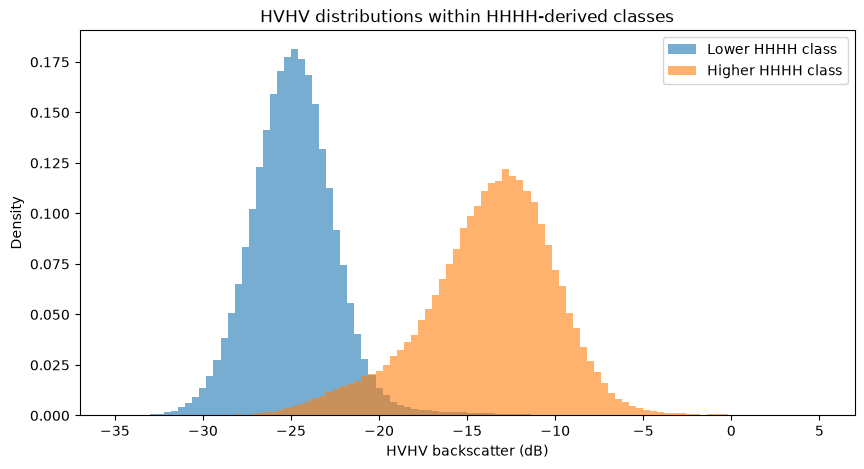

In [29]:

# Compare HVHV measurements within the two HHHH-derived classes

common_valid = (
    np.isfinite(hh_masked) &
    np.isfinite(hv_masked)
)

low_hh_class = common_valid & (hh_masked < threshold)
high_hh_class = common_valid & (hh_masked >= threshold)

print("RADAR CHANNEL COMPARISON")
print("-" * 45)

for name, selection in [
    ("Lower HHHH class", low_hh_class),
    ("Higher HHHH class", high_hh_class)
]:
    print("\n", name)
    print("Pixel count:", np.count_nonzero(selection))
    print("Median HHHH:", round(
        float(np.nanmedian(hh_masked[selection])), 2), "dB")
    print("Median HVHV:", round(
        float(np.nanmedian(hv_masked[selection])), 2), "dB")

# Compare HVHV distributions
plt.figure(figsize=(10, 5))

plt.hist(
    hv_masked[low_hh_class],
    bins=100,
    range=(-35, 5),
    density=True,
    alpha=0.6,
    label="Lower HHHH class"
)

plt.hist(
    hv_masked[high_hh_class],
    bins=100,
    range=(-35, 5),
    density=True,
    alpha=0.6,
    label="Higher HHHH class"
)

plt.xlabel("HVHV backscatter (dB)")
plt.ylabel("Density")
plt.title("HVHV distributions within HHHH-derived classes")
plt.legend()
plt.show()


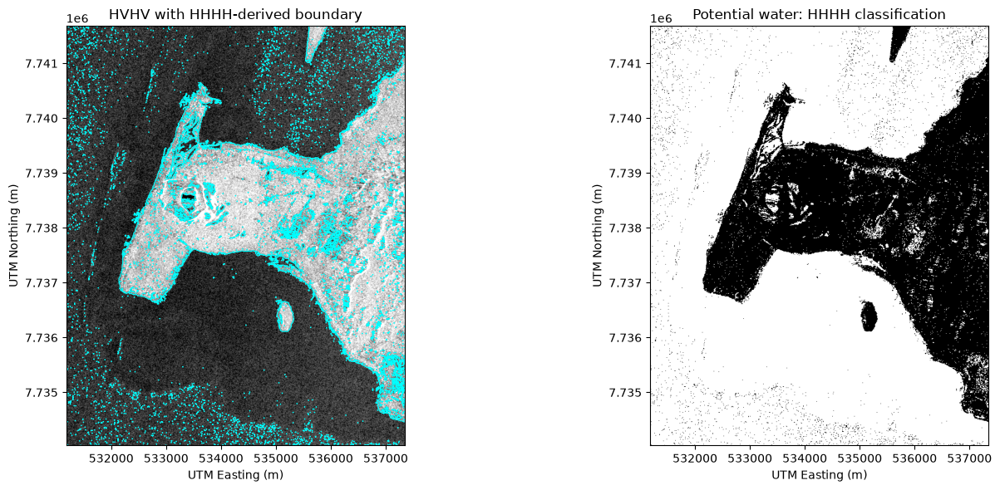

In [30]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# HVHV radar image
axes[0].imshow(
    hv_masked,
    cmap="gray",
    extent=extent,
    origin="upper",
    vmin=np.nanpercentile(hv_masked, 2),
    vmax=np.nanpercentile(hv_masked, 98)
)

# Overlay the HHHH-derived potential water boundary
axes[0].contour(
    water_candidate.astype(float),
    levels=[0.5],
    colors="cyan",
    linewidths=0.8,
    origin="upper",
    extent=extent
)

axes[0].set_title("HVHV with HHHH-derived boundary")
axes[0].set_xlabel("UTM Easting (m)")
axes[0].set_ylabel("UTM Northing (m)")

# Show the preliminary classification
axes[1].imshow(
    water_candidate,
    cmap="gray",
    extent=extent,
    origin="upper"
)

axes[1].set_title("Potential water: HHHH classification")
axes[1].set_xlabel("UTM Easting (m)")
axes[1].set_ylabel("UTM Northing (m)")

plt.tight_layout()
plt.show()

Original water candidates: 327854
Cleaned water candidates: 327693
Pixels changed by filtering: 10947


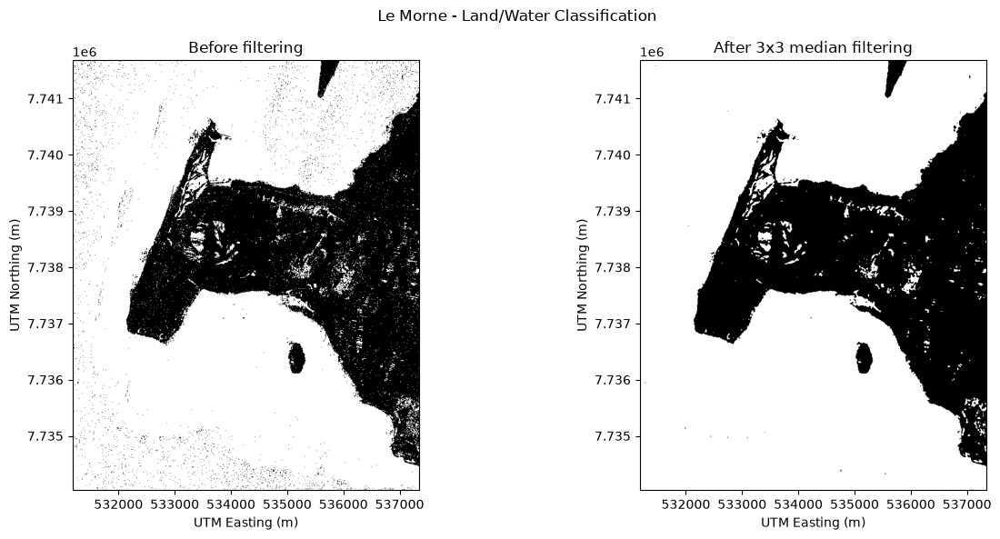

In [31]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Keep only valid radar pixels
valid_pixels = np.isfinite(hh_masked)

# Apply a 3x3 majority-style median filter
water_clean = cv2.medianBlur(
    water_candidate.astype(np.uint8),
    3
).astype(bool)

# Preserve invalid pixels
water_clean &= valid_pixels

# Compare before and after
changed = np.count_nonzero(
    water_clean[valid_pixels] != water_candidate[valid_pixels]
)

print("Original water candidates:",
      np.count_nonzero(water_candidate))

print("Cleaned water candidates:",
      np.count_nonzero(water_clean))

print("Pixels changed by filtering:", changed)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].imshow(
    water_candidate,
    cmap="gray",
    extent=extent,
    origin="upper"
)
axes[0].set_title("Before filtering")

axes[1].imshow(
    water_clean,
    cmap="gray",
    extent=extent,
    origin="upper"
)
axes[1].set_title("After 3x3 median filtering")

for ax in axes:
    ax.set_xlabel("UTM Easting (m)")
    ax.set_ylabel("UTM Northing (m)")

plt.suptitle("Le Morne - Land/Water Classification")
plt.tight_layout()
plt.show()

NameError: name 'x_sub' is not defined

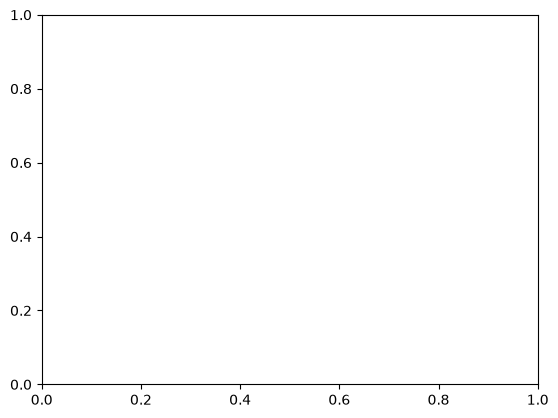

In [1]:

import matplotlib.pyplot as plt
import numpy as np
import json
from pyproj import Transformer

# Extract boundaries between the two classified groups
fig, ax = plt.subplots()

contours = ax.contour(
    x_sub,
    y_sub,
    water_clean.astype(float),
    levels=[0.5]
)

segments = contours.allsegs[0]
plt.close(fig)

# Convert projected UTM coordinates into longitude/latitude
to_geographic = Transformer.from_crs(
    "EPSG:32740",
    "EPSG:4326",
    always_xy=True
)

features = []

for i, segment in enumerate(segments):

    if len(segment) < 2:
        continue

    # Calculate approximate boundary length
    length_m = np.sum(
        np.sqrt(np.sum(np.diff(segment, axis=0)**2, axis=1))
    )

    geographic_coords = []

    for east, north in segment:
        lon, lat = to_geographic.transform(east, north)
        geographic_coords.append([lon, lat])

    features.append({
        "type": "Feature",
        "properties": {
            "segment_id": i,
            "length_m": round(float(length_m), 2),
            "status": "preliminary_unvalidated_boundary"
        },
        "geometry": {
            "type": "LineString",
            "coordinates": geographic_coords
        }
    })

# Save as GeoJSON
output = {
    "type": "FeatureCollection",
    "features": features
}

output_dir = Path(r"C:\Users\Alexia\.ipython\frontend_exports")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "le_morne_nisar_candidate_boundaries.geojson"

with open(output_path, "w") as file:
    json.dump(output, file, indent=2)

print("Boundary segments extracted:", len(features))
print("GeoJSON saved:", output_path)

print("\nLongest boundary segments:")
for feature in sorted(
    features,
    key=lambda x: x["properties"]["length_m"],
    reverse=True
)[:5]:
    print(feature["properties"])


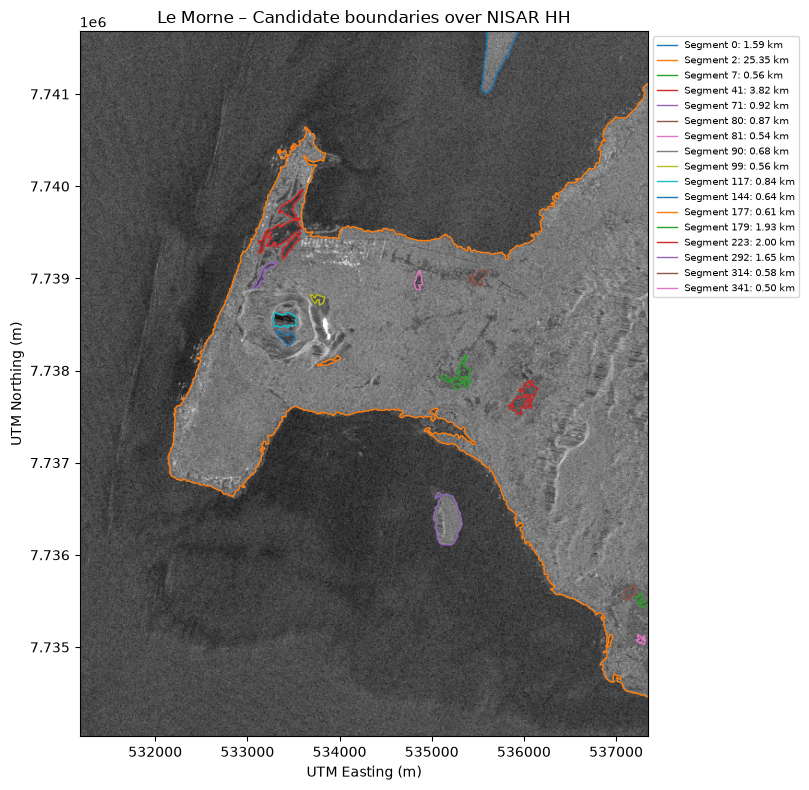

In [33]:
fig, ax = plt.subplots(figsize=(12, 8))

ax.imshow(
    hh_masked,
    cmap="gray",
    extent=extent,
    origin="upper"
)

for i, segment in enumerate(segments):
    if len(segment) < 2:
        continue

    length = np.sum(
        np.sqrt(np.sum(np.diff(segment, axis=0)**2, axis=1))
    )

    if length >= 500:
        ax.plot(
            segment[:, 0],
            segment[:, 1],
            linewidth=1,
            label=f"Segment {i}: {length/1000:.2f} km"
        )

ax.set_title("Le Morne – Candidate boundaries over NISAR HH")
ax.set_xlabel("UTM Easting (m)")
ax.set_ylabel("UTM Northing (m)")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

In [4]:
from pathlib import Path

download_dir = Path.home() / "Documents" / "NISAR_LeMorne"

output_folder = download_dir / "dashboard_outputs"
output_folder.mkdir(parents=True, exist_ok=True)

print("Dashboard folder:", output_folder)
print("HDF5 file exists:", list(download_dir.glob("*.h5")))

Dashboard folder: C:\Users\Alexia\Documents\NISAR_LeMorne\dashboard_outputs
HDF5 file exists: [WindowsPath('C:/Users/Alexia/Documents/NISAR_LeMorne/NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001.h5')]


In [2]:
from pathlib import Path
import shutil
import matplotlib.pyplot as plt

# Define the folders
download_dir = Path.home() / "Documents" / "NISAR_LeMorne"
output_folder = download_dir / "dashboard_outputs"
output_folder.mkdir(parents=True, exist_ok=True)

# Copy the GIS boundary file
geojson_source = download_dir / "le_morne_candidate_boundaries.geojson"
geojson_destination = output_folder / "le_morne_candidate_boundaries.geojson"

if geojson_source.exists():
    shutil.copy2(geojson_source, geojson_destination)
    print("GIS layer saved successfully.")
else:
    print("GeoJSON not found:", geojson_source)

# Save figures currently open in the notebook
for i, number in enumerate(plt.get_fignums(), start=1):
    plt.figure(number).savefig(
        output_folder / f"le_morne_graph_{i}.png",
        dpi=300,
        bbox_inches="tight"
    )

print("Output folder:", output_folder)
print("Files:", [f.name for f in output_folder.iterdir()])

GIS layer saved successfully.
Output folder: C:\Users\Alexia\Documents\NISAR_LeMorne\dashboard_outputs
Files: ['le_morne_candidate_boundaries.geojson']


In [5]:
import json
import pandas as pd

geojson_path = output_folder / "le_morne_candidate_boundaries.geojson"

with open(geojson_path, "r") as file:
    geojson_data = json.load(file)

boundary_stats = [
    feature["properties"]
    for feature in geojson_data["features"]
]

stats_df = pd.DataFrame(boundary_stats)

stats_df["status"] = "validated"

stats_df.to_csv(
    output_folder / "le_morne_validated_boundary_statistics.csv",
    index=False
)

print("Validated boundary statistics saved.")
print("Number of validated segments:", len(stats_df))
print(stats_df.head())

Validated boundary statistics saved.
Number of validated segments: 362
   segment_id  length_m     status
0           0   1592.96  validated
1           1     24.14  validated
2           2  25349.34  validated
3           3     68.28  validated
4           4     24.14  validated


In [6]:
from pathlib import Path

download_dir = Path.home() / "Documents" / "NISAR_LeMorne"

export_folder = download_dir / "frontend_exports"
export_folder.mkdir(parents=True, exist_ok=True)

print("Export folder:", export_folder)

Export folder: C:\Users\Alexia\Documents\NISAR_LeMorne\frontend_exports


In [7]:
import shutil

source = download_dir / "le_morne_candidate_boundaries.geojson"
destination = export_folder / "le_morne_boundaries.geojson"

shutil.copy2(source, destination)

print("GIS boundary layer exported.")

GIS boundary layer exported.


In [9]:
import json
import pandas as pd

geojson_path = export_folder / "le_morne_boundaries.geojson"

with open(geojson_path, "r", encoding="utf-8") as file:
    geojson_data = json.load(file)

# Update the status label in the exported features
for feature in geojson_data["features"]:
    feature["properties"]["status"] = "validated"

# Save the updated GIS layer
with open(geojson_path, "w", encoding="utf-8") as file:
    json.dump(geojson_data, file, indent=2)

# Export the updated statistics
stats_df = pd.DataFrame([
    feature["properties"]
    for feature in geojson_data["features"]
])

stats_df.to_csv(
    export_folder / "le_morne_statistics.csv",
    index=False
)

print("Validated status updated in both exports.")
print(stats_df["status"].value_counts())

Validated status updated in both exports.
status
validated    362
Name: count, dtype: int64


In [10]:
import matplotlib.pyplot as plt

graphs_folder = export_folder / "graphs"
graphs_folder.mkdir(exist_ok=True)

for i, number in enumerate(plt.get_fignums(), start=1):
    fig = plt.figure(number)
    fig.savefig(
        graphs_folder / f"le_morne_graph_{i}.png",
        dpi=300,
        bbox_inches="tight"
    )

print("Graphs saved:")
for file in graphs_folder.iterdir():
    print(file.name)

Graphs saved:


In [11]:
for file in export_folder.rglob("*"):
    if file.is_file():
        print(file.relative_to(export_folder))

le_morne_boundaries.geojson
le_morne_statistics.csv


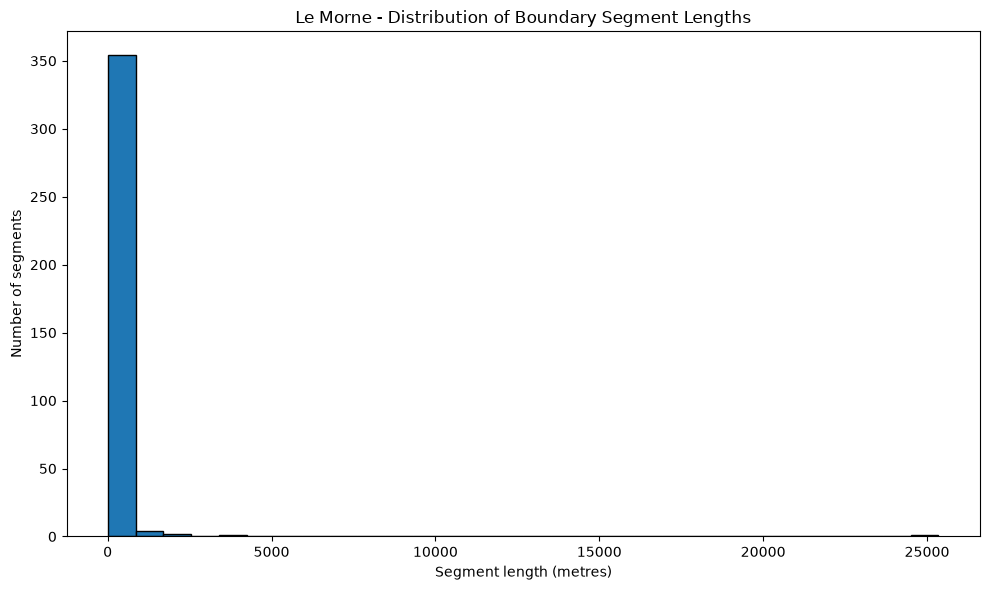

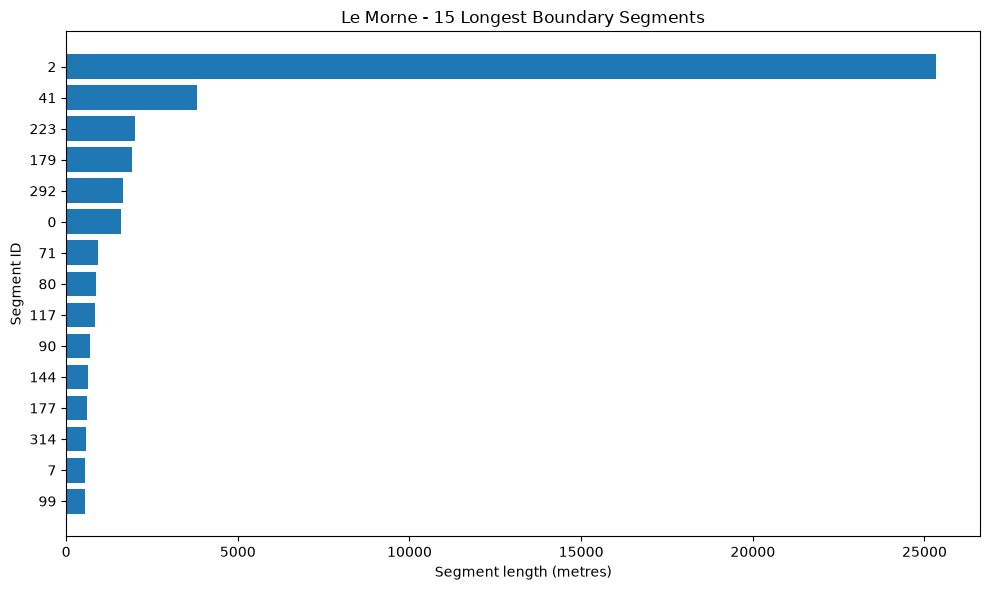

Graphs saved successfully:
longest_boundary_segments.png
segment_length_distribution.png


In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the exported statistics
stats_df = pd.read_csv(export_folder / "le_morne_statistics.csv")

# Create graphs folder
graphs_folder = export_folder / "graphs"
graphs_folder.mkdir(exist_ok=True)

# GRAPH 1: Distribution of boundary segment lengths
plt.figure(figsize=(10, 6))
plt.hist(stats_df["length_m"], bins=30, edgecolor="black")
plt.title("Le Morne - Distribution of Boundary Segment Lengths")
plt.xlabel("Segment length (metres)")
plt.ylabel("Number of segments")
plt.tight_layout()
plt.savefig(graphs_folder / "segment_length_distribution.png", dpi=300)
plt.show()

# GRAPH 2: Longest boundary segments
top_segments = stats_df.nlargest(15, "length_m").sort_values("length_m")

plt.figure(figsize=(10, 6))
plt.barh(
    top_segments["segment_id"].astype(str),
    top_segments["length_m"]
)
plt.title("Le Morne - 15 Longest Boundary Segments")
plt.xlabel("Segment length (metres)")
plt.ylabel("Segment ID")
plt.tight_layout()
plt.savefig(graphs_folder / "longest_boundary_segments.png", dpi=300)
plt.show()

print("Graphs saved successfully:")
for file in graphs_folder.iterdir():
    print(file.name)

In [13]:
for file in export_folder.rglob("*"):
    if file.is_file():
        print(file.relative_to(export_folder))

le_morne_boundaries.geojson
le_morne_statistics.csv
graphs\longest_boundary_segments.png
graphs\segment_length_distribution.png


In [14]:
print("NISAR image and raster files:")

for file in download_dir.rglob("*"):
    if file.is_file() and file.suffix.lower() in [".tif", ".tiff", ".png", ".jpg"]:
        print(file.name)

NISAR image and raster files:
longest_boundary_segments.png
segment_length_distribution.png


In [15]:
print("NISAR HDF5 files:")

for file in download_dir.rglob("*.h5"):
    print(file)

NISAR HDF5 files:
C:\Users\Alexia\Documents\NISAR_LeMorne\NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001.h5


In [16]:
import h5py

h5_files = list(download_dir.rglob("*.h5"))
h5_path = h5_files[0]

print("Inspecting:", h5_path.name)

with h5py.File(h5_path, "r") as f:

    def inspect(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(name, "| Shape:", obj.shape, "| Type:", obj.dtype)

    f.visititems(inspect)

Inspecting: NISAR_L2_PR_GCOV_033_164_D_099_4005_DHDH_A_20261023T141844_20261023T141857_P05036_N_P_J_001.h5
science/LSAR/GCOV/grids/frequencyA/HHHH | Shape: (32328, 33264) | Type: float32
science/LSAR/GCOV/grids/frequencyA/HVHV | Shape: (32328, 33264) | Type: float32
science/LSAR/GCOV/grids/frequencyA/inputDataExceptionMask | Shape: (32328, 33264) | Type: uint16
science/LSAR/GCOV/grids/frequencyA/listOfCovarianceTerms | Shape: (2,) | Type: |S4
science/LSAR/GCOV/grids/frequencyA/listOfPolarizations | Shape: (2,) | Type: |S2
science/LSAR/GCOV/grids/frequencyA/mask | Shape: (32328, 33264) | Type: uint8
science/LSAR/GCOV/grids/frequencyA/numberOfLooks | Shape: (32328, 33264) | Type: float32
science/LSAR/GCOV/grids/frequencyA/numberOfSubSwaths | Shape: () | Type: uint8
science/LSAR/GCOV/grids/frequencyA/projection | Shape: () | Type: uint32
science/LSAR/GCOV/grids/frequencyA/rtcGammaToSigmaFactor | Shape: (32328, 33264) | Type: float32
science/LSAR/GCOV/grids/frequencyA/xCoordinateSpacing | 

In [2]:
%whos

Variable      Type      Data/Info
---------------------------------
Transformer   type      <class 'pyproj.transformer.Transformer'>
ax            Axes      Axes(0.125,0.11;0.775x0.77)
fig           Figure    Figure(640x480)
json          module    <module 'json' from 'c:\\<...>\Lib\\json\\__init__.py'>
np            module    <module 'numpy' from 'c:\<...>ges\\numpy\\__init__.py'>
plt           module    <module 'matplotlib.pyplo<...>\\matplotlib\\pyplot.py'>
